# 💵 Salary Prediction using Linear Regression

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Salary_dataset.csv')

In [3]:
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [4]:
# explore dataset

In [5]:
df.shape

(30, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [7]:
df.describe() # stats summary

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


In [8]:
df.isnull().sum()

Unnamed: 0         0
YearsExperience    0
Salary             0
dtype: int64

In [9]:
# df = df.dropna() if there were missing values 
# since there were no missing values there is no need of this step

In [10]:
# dropped the unnamed column as it was not useful
df = df.drop("Unnamed: 0", axis= 1)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [12]:
# features and target

X = df[['YearsExperience']]
y = df['Salary']

In [13]:
# split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, random_state = 42)

In [14]:
# create model
model = LinearRegression()

In [15]:
# train model
model.fit(X_train, y_train)
# The fit() method trains the model using the provided input features and target values.

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
# make prediction
y_pred = model.predict(X_test)
print(y_pred)

[115791.21011287  71499.27809463 102597.86866063  75268.80422384
  55478.79204548  60190.69970699]


In [17]:
# evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE: ',mae)
print('MSE: ',mse)
print('RMSE: ',rmse)
print('R2 Score: ',r2)

MAE:  6286.453830757745
MSE:  49830096.855908334
RMSE:  7059.043621901506
R2 Score:  0.9024461774180498


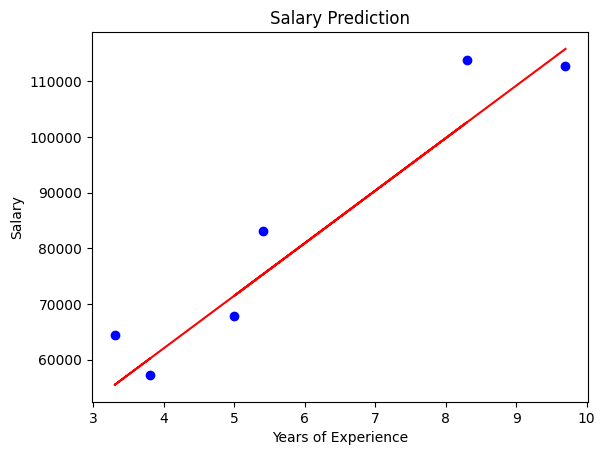

In [18]:
# visualize predictions

plt.scatter(X_test, y_test, color='blue')

plt.plot(X_test, y_pred, color='red')

plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.title('Salary Prediction')

plt.show()

In [25]:
# predict on new salary
import math
new_data = pd.DataFrame({
    'YearsExperience': [9]
})

prediction = model.predict(new_data)

print('Predicted Salary: ', math.floor(prediction[0]))

Predicted Salary:  109194
